# 03 · Evaluate and compare

**Question:** is our fine-tuned model better than the baselines, and where does it still fail?

This notebook (1) measures a model on the test images, (2) compares it with the saved results of the baselines and earlier models,
(3) shows a per-class chart and the confusion matrix, and (4) lists the typical mistakes with pictures.

Default is a **fast 10-image run**; set `FULL_RUN = True` to use all 80 test images. The test set is never used to choose settings:
it is looked at only once, at the end.

## 1. Find the project and set the parameters

In [1]:
# Find the project root (the folder that contains PROJECT_PLAN.md) and work from there,
# so every path below is relative to the project root no matter where Jupyter was started.
import os, sys
from pathlib import Path

here = Path.cwd().resolve()
for folder in [here, *here.parents]:
    if (folder / "PROJECT_PLAN.md").exists():
        os.chdir(folder)
        break
else:
    raise SystemExit("PROJECT_PLAN.md not found: start Jupyter inside the project folder")
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))   # lets us import small helpers from src/ if we need them
print("project root folder:", ROOT.name)

project root folder: comp_vision


In [2]:
# ---- parameters: change things here ----
FULL_RUN = False
WEIGHTS = "results/weights/best.pt"     # model to evaluate (the one the website uses)
SPLIT = "test"
MAX_IMAGES = None if FULL_RUN else 10
DATA_YAML = "data/dataset/data.yaml"
IMGSZ = 640
CONF = 0.25                              # confidence a box needs to be counted in the failure-case section

import torch
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("weights:", WEIGHTS, "| device:", DEVICE, "| images:", MAX_IMAGES or "all")

weights: results/weights/best.pt | device: 0 | images: 10


## 2. Load the images and labels

In [3]:
from IPython.display import display

import yaml

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
cfg = yaml.safe_load(Path(DATA_YAML).read_text())
NAMES = {int(k): v for k, v in cfg["names"].items()}            # our classes: 0 dog, 1 goat, 2 cow, 3 cat, 4 sheep

def list_images(split):
    """All image files of a split, e.g. data/dataset/images/test/*.jpg (sorted, so runs are repeatable)."""
    folder = Path(cfg["path"]) / cfg[split]
    return sorted(p for p in folder.rglob("*") if p.suffix.lower() in IMG_EXT)

def label_file(img):
    """The YOLO label file of an image: .../images/test/a.jpg -> .../labels/test/a.txt"""
    return Path(str(img).replace("/images/", "/labels/")).with_suffix(".txt")

images = list_images(SPLIT)[:MAX_IMAGES]                         # [:None] keeps everything
n_boxes = sum(len([l for l in label_file(i).read_text().splitlines() if l.strip()]) for i in images if label_file(i).exists())
print(f"{len(images)} images from split '{SPLIT}', {n_boxes} labelled boxes")

10 images from split 'test', 22 labelled boxes


## 3. Measure the model
Same evaluation code as in notebook 01 (the official Ultralytics validation on a throw-away dataset). Our model already uses our class
numbers, so no translation is needed (`cls_map=None`). Precision = how many predictions were right; recall = how many real animals were found.

In [4]:
import shutil, time
import numpy as np
import pandas as pd
from ultralytics import YOLO

TMP = ROOT / "runs/notebooks/_eval_tmp"            # scratch dataset, rebuilt on every evaluation (runs/ is git-ignored)

def build_tmp_dataset(imgs, cls_map):
    """Copy-free dataset for the official validator: symlink the images and write their labels using the MODEL's class ids.
    cls_map = {model_class_id: our_class_id}. Boxes of classes the model cannot predict are dropped (their AP becomes NaN).
    cls_map=None means the model already uses our ids."""
    inverse = {ours: theirs for theirs, ours in cls_map.items()} if cls_map else None
    shutil.rmtree(TMP, ignore_errors=True)
    (TMP / "images/test").mkdir(parents=True); (TMP / "labels/test").mkdir(parents=True)
    for img in imgs:
        (TMP / "images/test" / img.name).symlink_to(img.resolve())
        lines = []
        if label_file(img).exists():
            for line in label_file(img).read_text().splitlines():
                parts = line.split()
                if not parts:
                    continue
                ours = int(float(parts[0]))
                if inverse is None:
                    lines.append(line)
                elif ours in inverse:
                    lines.append(" ".join([str(inverse[ours])] + parts[1:]))
        (TMP / "labels/test" / (img.stem + ".txt")).write_text("\n".join(lines) + ("\n" if lines else ""))

def evaluate_model(weights, imgs, cls_map=None, plots=False):
    """Official Ultralytics validation (conf 0.001, NMS IoU 0.7, batch 1) + FPS. Returns one row of metrics."""
    model = YOLO(str(weights))
    build_tmp_dataset(imgs, cls_map)
    (TMP / "data.yaml").write_text(yaml.safe_dump({"path": str(TMP), "train": "images/test", "val": "images/test",
                                                   "test": "images/test", "names": {int(k): v for k, v in model.names.items()}}))
    r = model.val(data=str(TMP / "data.yaml"), split="test", imgsz=IMGSZ, batch=1, conf=0.001, iou=0.7, device=DEVICE,
                  plots=plots, verbose=False, project=str(TMP / "val"), name="v", exist_ok=True, save=False)
    per_class = {}
    for k, cls_id in enumerate(r.box.ap_class_index):                      # AP50 of every class that has ground truth
        per_class[cls_map[int(cls_id)] if cls_map else int(cls_id)] = float(r.box.ap50[k])
    model.predict(str(imgs[0]), imgsz=IMGSZ, verbose=False, device=DEVICE)  # warm-up (first call is slow)
    t0 = time.perf_counter()
    for img in imgs:
        model.predict(str(img), imgsz=IMGSZ, conf=0.25, verbose=False, device=DEVICE)
    sec = (time.perf_counter() - t0) / len(imgs)
    row = {"images": len(imgs), "precision": float(r.box.mp), "recall": float(r.box.mr), "mAP50": float(r.box.map50),
           "mAP50-95": float(r.box.map), "FPS": 1 / sec}
    for cls_id, name in NAMES.items():
        row[f"AP50_{name}"] = per_class.get(cls_id, np.nan)                # NaN = no ground truth / not supported
    return row, r

In [5]:
row, val_result = evaluate_model(WEIGHTS, images, cls_map=None, plots=True)
this_run = pd.DataFrame([{"model": "this notebook run", **row}])
this_run.round(3)

Ultralytics 8.4.213 🚀 Python-3.11.17 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 5822MiB)


Model summary (fused): 72 layers, 11,127,519 parameters, 0 gradients, 28.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5843.5±1039.1 MB/s, size: 298.9 KB)


val: Scanning runs/notebooks/_eval_tmp/labels/test... 10 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 2.4Kit/s 0.0s

val: New cache created: runs/notebooks/_eval_tmp/labels/test.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 10% ━─────────── 1/10 1.0it/s 0.3s<8.7s

... (3 outputs left out)

                   all         10         22      0.968      0.612      0.743      0.472


Speed: 1.0ms preprocess, 33.1ms inference, 0.0ms loss, 1.6ms postprocess per image


Results saved to runs/notebooks/_eval_tmp/val/v


,model,images,precision,recall,mAP50,mAP50-95,FPS,AP50_dog,AP50_goat,AP50_cow,AP50_cat,AP50_sheep
0,this notebook run,10,0.968,0.612,0.743,0.472,59.512,0.495,0.863,0.871,NaN,NaN


## 4. Compare with the recorded results
`results/comparison.csv` holds the official 80-image test numbers of the two baselines and our fine-tuned models.
Your run is shown separately: with only 10 images it is **not** comparable to those rows (set `FULL_RUN = True` to compare fairly).

In [6]:
comparison = pd.read_csv("results/comparison.csv")
cols = ["model", "images", "mAP50", "mAP50-95", "precision", "recall", "FPS"]
display(comparison[cols].round(3))
display(this_run[cols].round(3))

,model,images,mAP50,mAP50-95,precision,recall,FPS
0,baseline_coco_yolov8n,80,0.810,0.643,0.799,0.705,114.676
1,baseline_oiv7_yolov8m,80,0.906,0.765,0.794,0.885,55.863
2,finetuned_v1_yolov8s_freeze10,80,0.854,0.577,0.851,0.808,77.746
3,finetuned_v2A_yolov8s_freeze10,80,0.842,0.589,0.803,0.763,97.719


,model,images,mAP50,mAP50-95,precision,recall,FPS
0,this notebook run,10,0.743,0.472,0.968,0.612,59.512


## 5. Per-class chart
Average numbers can hide a weak class. Bars show AP50 per animal; "n/a" means the model has no such class (COCO has no goat)
or the test set has no examples of it (the frozen test set has no sheep).

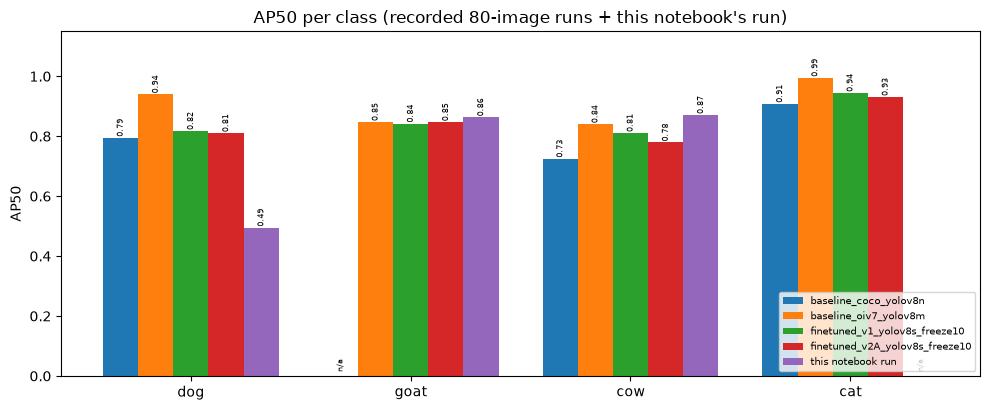

In [7]:
import matplotlib.pyplot as plt

classes = [n for n in NAMES.values() if comparison[f"AP50_{n}"].notna().any() or this_run[f"AP50_{n}"].notna().any()]
table = pd.concat([comparison, this_run], ignore_index=True)
width = 0.8 / len(table)
fig, ax = plt.subplots(figsize=(10, 4.2))
for k, (_, r) in enumerate(table.iterrows()):
    vals = [r[f"AP50_{c}"] for c in classes]
    xs = [i + (k - (len(table) - 1) / 2) * width for i in range(len(classes))]
    ax.bar(xs, [0 if v != v else v for v in vals], width, label=r["model"])
    for xi, v in zip(xs, vals):
        ax.text(xi, 0.02 if v != v else v + 0.01, "n/a" if v != v else f"{v:.2f}", ha="center", fontsize=6, rotation=90)
ax.set_xticks(range(len(classes)), classes); ax.set_ylim(0, 1.15); ax.set_ylabel("AP50")
ax.legend(fontsize=7, loc="lower right"); ax.set_title("AP50 per class (recorded 80-image runs + this notebook's run)")
plt.tight_layout(); plt.show()

## 6. Confusion matrix
Rows are the predicted class, columns the true class (each column adds up to 1). A bright diagonal is good. The "background" row/column
shows missed animals (true animal, predicted nothing) and false alarms (predicted animal, nothing there).
This is the matrix of the run in section 3 (so it also uses only the images selected above).

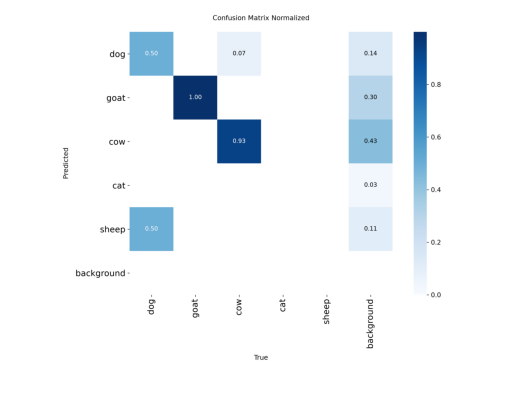

In [8]:
import matplotlib.image as mpimg

cm_png = Path(val_result.save_dir) / "confusion_matrix_normalized.png"
plt.figure(figsize=(6.5, 6)); plt.imshow(mpimg.imread(cm_png)); plt.axis("off"); plt.show()

## 7. Failure cases
We compare each prediction with the labelled boxes (a prediction "matches" a box when the boxes overlap by IoU >= 0.5) and sort the mistakes:
- **wrong class**: right place, wrong animal
- **miss**: a labelled animal nobody predicted
- **false positive**: a prediction where nothing is labelled

Green = label, red = prediction.

{'wrong_class': 1, 'miss': 6, 'false_positive': 2} events in 10 images


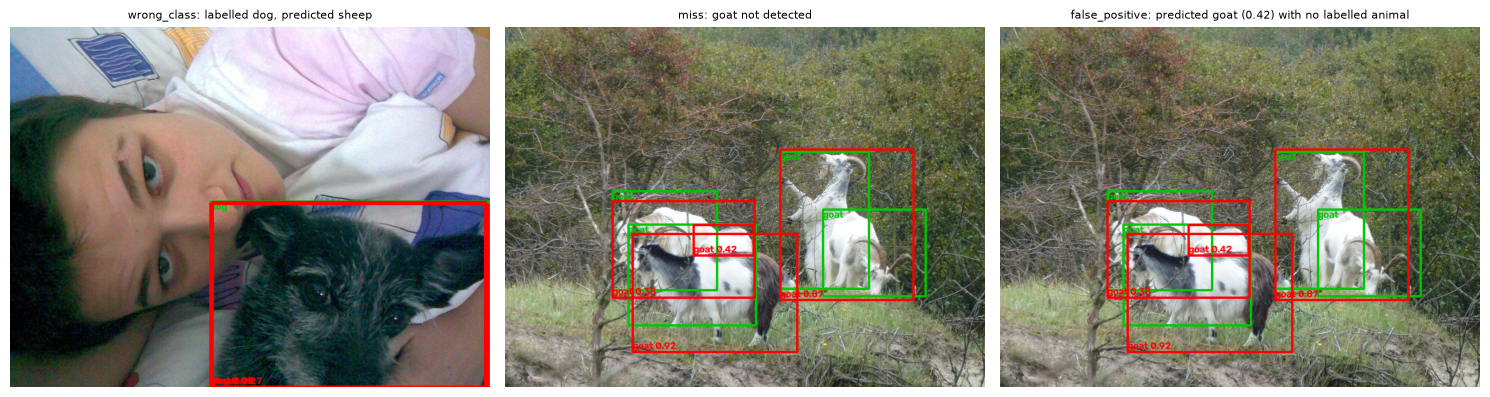

In [9]:
import cv2

def iou(a, b):
    """Overlap of two boxes (x1, y1, x2, y2): intersection area / union area."""
    iw = max(0, min(a[2], b[2]) - max(a[0], b[0])); ih = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = iw * ih
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter + 1e-9)

model = YOLO(WEIGHTS)
found = {"wrong_class": [], "miss": [], "false_positive": []}
for img_path in images:
    img = cv2.imread(str(img_path)); h, w = img.shape[:2]
    truth = []                                                     # labelled boxes in pixels
    if label_file(img_path).exists():
        for line in label_file(img_path).read_text().splitlines():
            t = line.split()
            if len(t) == 5:
                c, x, y, bw, bh = int(t[0]), *map(float, t[1:])
                truth.append((c, [(x - bw / 2) * w, (y - bh / 2) * h, (x + bw / 2) * w, (y + bh / 2) * h]))
    out = model.predict(img, conf=CONF, imgsz=IMGSZ, verbose=False, device=DEVICE)[0].boxes
    preds = [(int(c), float(s), xy) for c, s, xy in zip(out.cls.tolist(), out.conf.tolist(), out.xyxy.tolist())]
    used = set()
    for c, box in truth:
        best_iou, j = max(((iou(box, p[2]), j) for j, p in enumerate(preds)), default=(0, -1))
        if best_iou >= 0.5:
            used.add(j)
            if preds[j][0] != c:
                found["wrong_class"].append((img_path, truth, preds, f"labelled {NAMES[c]}, predicted {NAMES[preds[j][0]]}"))
        else:
            found["miss"].append((img_path, truth, preds, f"{NAMES[c]} not detected"))
    for j, p in enumerate(preds):
        if j not in used and all(iou(p[2], t[1]) < 0.3 for t in truth):
            found["false_positive"].append((img_path, truth, preds, f"predicted {NAMES[p[0]]} ({p[1]:.2f}) with no labelled animal"))

print({k: len(v) for k, v in found.items()}, f"events in {len(images)} images")

def draw(img_path, truth, preds):
    img = cv2.imread(str(img_path))
    for c, b in truth:
        cv2.rectangle(img, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), (0, 200, 0), 3)
        cv2.putText(img, NAMES[c], (int(b[0]), int(b[1]) + 18), 0, 0.7, (0, 200, 0), 2)
    for c, s, b in preds:
        cv2.rectangle(img, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), (0, 0, 255), 3)
        cv2.putText(img, f"{NAMES[c]} {s:.2f}", (int(b[0]), int(b[3]) - 6), 0, 0.7, (0, 0, 255), 2)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

shown = [(k, v[0]) for k, v in found.items() if v]
if shown:
    fig, axs = plt.subplots(1, len(shown), figsize=(5 * len(shown), 4), squeeze=False)
    for ax, (kind, (p, truth, preds, why)) in zip(axs[0], shown):
        ax.imshow(draw(p, truth, preds)); ax.axis("off"); ax.set_title(f"{kind}: {why}", fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("no mistakes in this small sample; try FULL_RUN = True")

### Failure examples from the full 80-image test run
Saved by `src/make_plots.py` (explanations: `results/failure_cases.md`). A group scene, a wrong class, a miss and a false positive.

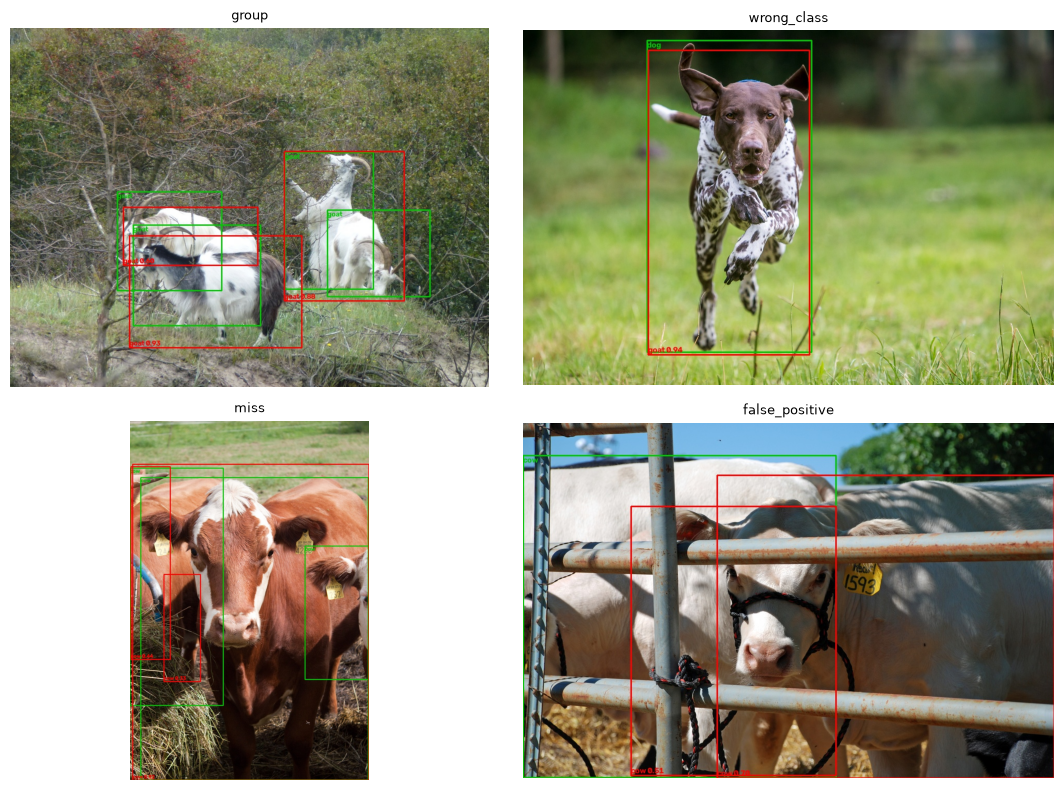

In [10]:
saved = ["failure_group", "failure_wrong_class", "failure_miss", "failure_false_positive"]
fig, axs = plt.subplots(2, 2, figsize=(11, 8))
for ax, name in zip(axs.ravel(), saved):
    f = Path(f"results/figures/{name}.jpg")
    if f.exists():
        ax.imshow(mpimg.imread(f))
    ax.set_title(name.replace("failure_", ""), fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## What to take away
- Compare models only on the same images (use `FULL_RUN = True`).
- Look at the per-class bars and the confusion matrix, not only at mAP: a good average can hide a weak class.
- Known caveats: the test images are Open Images (not Nepal street photos), and the Open Images baseline may have seen them in training.